In [26]:
from ultralytics import YOLOE
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

model = YOLOE("yoloe-26m-seg.pt")

In [27]:
img_path = "../data/test-penguin.jpeg"

In [28]:
# Set custom open-world classes
model.set_classes(["penguins"])

In [29]:
results = model.predict(img_path, device="mps")


image 1/1 /Users/krish/Workspace/robotics-exp/02-vlm/../data/test-penguin.jpeg: 448x640 3 penguinss, 26.5ms
Speed: 1.1ms preprocess, 26.5ms inference, 12.9ms postprocess per image at shape (1, 3, 448, 640)


In [36]:
print(results[0].boxes)

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([0., 0., 0.], device='mps:0')
conf: tensor([0.3025, 0.2988, 0.2627], device='mps:0')
data: tensor([[4.8953e+02, 1.9395e+02, 5.5841e+02, 3.4541e+02, 3.0249e-01, 0.0000e+00],
        [2.3074e+02, 1.9052e+02, 3.7207e+02, 3.7933e+02, 2.9880e-01, 0.0000e+00],
        [5.4215e+02, 2.2023e+02, 6.7019e+02, 3.9427e+02, 2.6272e-01, 0.0000e+00]], device='mps:0')
id: None
is_track: False
orig_shape: (630, 945)
shape: torch.Size([3, 6])
xywh: tensor([[523.9698, 269.6784,  68.8705, 151.4662],
        [301.4073, 284.9241, 141.3260, 188.8039],
        [606.1722, 307.2513, 128.0411, 174.0437]], device='mps:0')
xywhn: tensor([[0.5545, 0.4281, 0.0729, 0.2404],
        [0.3189, 0.4523, 0.1496, 0.2997],
        [0.6415, 0.4877, 0.1355, 0.2763]], device='mps:0')
xyxy: tensor([[489.5345, 193.9453, 558.4051, 345.4115],
        [230.7443, 190.5222, 372.0703, 379.3261],
        [542.1516, 220.2295, 670.1927, 394.2731]], device='mps:0')
xyxyn:

In [37]:
print(results[0].masks) 

ultralytics.engine.results.Masks object with attributes:

data: tensor([[[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]],

        [[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]],

        [[0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]]], device='mps:0', dtype=torch.uint8)
orig_shape: (630, 945)
shape: torch.Size([3, 448, 640])
xy: [array([[     503.51,      194.75],
       [     502.03,      196.23],
       [     500.55,      196.23],
       [     499.08,       197.7],
       [     493.17,  

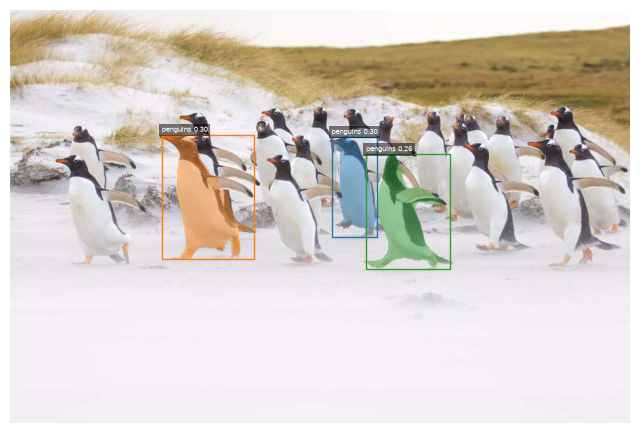

In [42]:
r = results[0]
img = r.orig_img[:, :, ::-1]  # BGR -> RGB
names = r.names
plt.figure(figsize=(8, 8))
plt.imshow(img)
for mask, box in zip(r.masks.xy, r.boxes):
    xs, ys = mask[:, 0], mask[:, 1]
    plt.fill(xs, ys, alpha=0.45)
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    plt.plot([x1, x2, x2, x1, x1], [y1, y1, y2, y2, y1], linewidth=1)
    label = names[int(box.cls[0])]
    conf = float(box.conf[0])
    plt.text(x1, y1 - 5, f"{label} {conf:.2f}", color="white", fontsize=5,
             bbox=dict(facecolor="black", alpha=0.5, pad=2, edgecolor="none"))
plt.axis("off")
plt.show()